In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1434s 8us/step
Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [3]:
resize_layer = layers.Resizing(64, 64)

x_train_resized = resize_layer(x_train)
x_test_resized = resize_layer(x_test)

print("Resized shape:", x_train_resized.shape)

Resized shape: (50000, 64, 64, 3)


In [6]:

# Convert uint8 to float32 and normalize
x_train_normalized = tf.cast(x_train_resized, tf.float32) / 255.0

x_test_normalized = tf.cast(x_test_resized, tf.float32) / 255.0

# Check minimum and maximum values
print("Minimum:", tf.reduce_min(x_train_normalized).numpy())
print("Maximum:", tf.reduce_max(x_train_normalized).numpy())

print("Training shape:", x_train_normalized.shape)
print("Testing shape:", x_test_normalized.shape)


Minimum: 0.0
Maximum: 1.0
Training shape: (50000, 64, 64, 3)
Testing shape: (10000, 64, 64, 3)


In [11]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

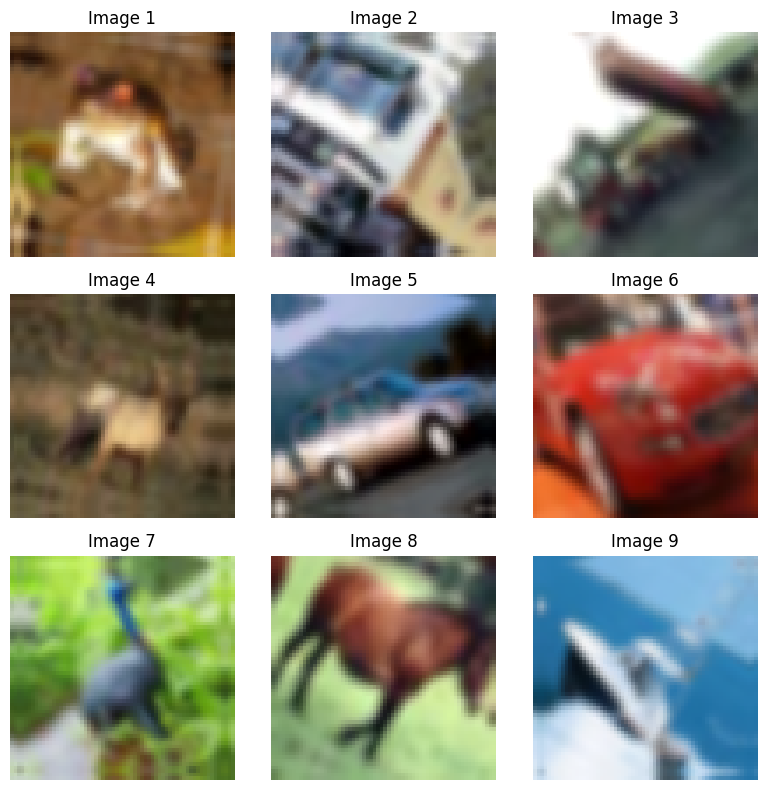

In [12]:
# Select 9 images
sample_images = x_train_normalized[:9]

# Apply augmentation
augmented_images = data_augmentation(
    sample_images,
    training=True
)

# Display images
plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_images[i].numpy())
    plt.axis("off")
    plt.title(f"Image {i+1}")

plt.tight_layout()
plt.show()